# RL-Based Dynamic Emergency Resource Allocation Using Real NYC EMS Data

### Upgraded research/placement version

This notebook implements a reproducible **data-driven emergency resource allocation simulator** using:

- Real NYC EMS Incident Dispatch Data from NYC Open Data.
- Real NYC hospital locations from NYC Open Data.
- Real hospital capacity information when available from New York State Department of Health.
- Real ZIP-level incident geography converted to ZIP centroids because NYC EMS does not publish exact incident coordinates for privacy.
- Real OpenStreetMap road geometry and Dijkstra shortest-path routing.
- Deep Q-Learning (DQN) for dynamic hospital selection.
- Strong non-RL baselines: nearest available, capacity-first, weighted distance-capacity heuristic, and random.
- Stress tests for normal, high-congestion, critical-shortage, and demand-surge conditions.
- Multiple random seeds with mean ± standard deviation.
- Metrics for travel time, overload/rejection, utilization, resource balance, critical-case performance, and reward.

> **Data honesty:** EMS incidents and hospital locations are real. Because public EMS data intentionally aggregates incident locations, the notebook uses ZIP centroids as spatial proxies. Live hospital occupancy is not available in the selected public sources, so occupancy and service duration are simulated dynamically. The project therefore remains a **real-data-grounded decision-support simulation**, not a clinical deployment system.

In [1]:
# Installation command (packages pre-installed in runtime)
print('Packages ready.')

Packages ready.


In [2]:
# ============================================================
# CELL 2 — IMPORTS, CONFIGURATION & REPRODUCIBILITY
# ============================================================
import os, re, json, math, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import networkx as nx
import osmnx as ox

import gymnasium as gym
from gymnasium import spaces
from rapidfuzz import process, fuzz
from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

FAST_MODE = False
EMS_LIMIT = 100_000 if FAST_MODE else 300_000
N_SIM_EVENTS = 8_000 if FAST_MODE else 20_000
MAX_HOSPITALS = 12
DQN_TIMESTEPS = 30_000 if FAST_MODE else 100_000
EVAL_EPISODES = 40 if FAST_MODE else 100
EVAL_SEEDS = [42, 7, 21, 99, 123]

CACHE_DIR = Path("results")
CACHE_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)

print("FAST_MODE:", FAST_MODE)
print("EMS_LIMIT:", EMS_LIMIT)
print("DQN_TIMESTEPS:", DQN_TIMESTEPS)

FAST_MODE: False
EMS_LIMIT: 300000
DQN_TIMESTEPS: 100000


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


## 1. Data sources

The primary demand source is the official NYC Open Data **EMS Incident Dispatch Data**. It is generated from the FDNY EMS Computer Aided Dispatch System and contains incident timing, call type, severity, response/travel variables, borough, dispatch area and other operational fields. The public dataset contains tens of millions of incidents and explicitly aggregates incident locations to protect privacy. citeturn0search0turn0search2

Hospital locations come from the NYC Open Data hospital dataset, which provides facility type, borough, facility name and geographic location. citeturn1search0turn1search2

The notebook also attempts to attach licensed/certified capacity from New York State Department of Health sources. Any unmatched capacity is explicitly labeled as estimated rather than silently presented as real. citeturn2search0

In [3]:
# ============================================================
# CELL 3 — SOCRATA HELPER
# ============================================================
def socrata_get_json(base_url, params, cache_file=None, timeout=60):
    if cache_file is not None and Path(cache_file).exists():
        with open(cache_file, "r", encoding="utf-8") as f:
            return json.load(f)

    r = requests.get(base_url, params=params, timeout=timeout)
    r.raise_for_status()
    data = r.json()

    if cache_file is not None:
        with open(cache_file, "w", encoding="utf-8") as f:
            json.dump(data, f)

    return data

def clean_name(x):
    x = str(x).upper()
    x = re.sub(r"[^A-Z0-9 ]+", " ", x)
    x = re.sub(r"\b(HOSPITAL|MEDICAL|CENTER|CENTRE|HEALTH|AND|THE)\b", " ", x)
    return re.sub(r"\s+", " ", x).strip()

In [4]:
# ============================================================
# CELL 4 — DOWNLOAD REAL NYC EMS DATA
# ============================================================
EMS_URL = "https://data.cityofnewyork.us/resource/76xm-jjuj.json"

EMS_COLUMNS = [
    "incident_id", "incident_datetime", "initial_call_type",
    "initial_severity_level_code", "final_call_type",
    "final_severity_level_code", "dispatch_response_seconds_qy",
    "incident_response_seconds_qy", "incident_travel_tm_seconds_qy",
    "incident_disposition_code", "borough", "incident_dispatch_area",
    "zipcode", "communitydistrict", "special_event_indicator",
    "standby_indicator", "transfer_indicator"
]

params = {
    "$select": ",".join(EMS_COLUMNS),
    "$where": (
        "incident_datetime between '2025-01-01T00:00:00' "
        "and '2025-12-31T23:59:59' "
        "AND zipcode IS NOT NULL "
        "AND initial_severity_level_code IS NOT NULL"
    ),
    "$order": "incident_datetime DESC",
    "$limit": EMS_LIMIT
}

ems_raw = pd.DataFrame(
    socrata_get_json(
        EMS_URL, params, cache_file=CACHE_DIR / "ems_2025.json"
    )
)

print("REAL NYC EMS shape:", ems_raw.shape)
display(ems_raw.head())

REAL NYC EMS shape: (300000, 17)


,incident_id,incident_datetime,initial_call_type,initial_severity_level_code,final_call_type,final_severity_level_code,dispatch_response_seconds_qy,incident_disposition_code,borough,incident_dispatch_area,zipcode,communitydistrict,special_event_indicator,standby_indicator,transfer_indicator,incident_response_seconds_qy,incident_travel_tm_seconds_qy
0,83008096,2025-12-31T23:59:35.000,OTHER,6,OTHER,6,0,CANCEL,BRONX,B5,10468,207,N,N,N,NaN,NaN
1,83008095,2025-12-31T23:59:29.000,UNKNOW,4,INJURY,5,1670,91,BRONX,B1,10451,201,N,N,N,2105,435
2,83008094,2025-12-31T23:59:17.000,INJURY,5,INJURY,5,0,CANCEL,MANHATTAN,M5,10021,108,N,N,N,NaN,NaN
3,83008093,2025-12-31T23:58:55.000,DRUG,5,DRUG,5,46,90,BROOKLYN,K6,11217,302,N,N,N,1220,1174
4,83008092,2025-12-31T23:58:46.000,EDP,7,EDPC,7,0,ZZZZZZ,QUEENS,Q6,11368,403,N,N,N,NaN,NaN


In [5]:
# ============================================================
# CELL 5 — EMS CLEANING & FEATURE ENGINEERING
# ============================================================
ems = ems_raw.copy()

ems["incident_datetime"] = pd.to_datetime(
    ems["incident_datetime"], errors="coerce"
)

for c in [
    "initial_severity_level_code",
    "final_severity_level_code",
    "dispatch_response_seconds_qy",
    "incident_response_seconds_qy",
    "incident_travel_tm_seconds_qy"
]:
    ems[c] = pd.to_numeric(ems[c], errors="coerce")

ems["zipcode"] = (
    ems["zipcode"].astype(str).str.extract(r"(\d{5})")[0]
)
ems["borough"] = ems["borough"].astype(str).str.upper().str.strip()

ems = ems.dropna(
    subset=[
        "incident_datetime", "zipcode",
        "initial_severity_level_code",
        "incident_travel_tm_seconds_qy"
    ]
).copy()

ems = ems[
    (ems["incident_travel_tm_seconds_qy"] >= 0) &
    (ems["incident_travel_tm_seconds_qy"] <= 3600)
].copy()

ems["hour"] = ems["incident_datetime"].dt.hour
ems["dow"] = ems["incident_datetime"].dt.dayofweek
ems["month"] = ems["incident_datetime"].dt.month
ems["is_weekend"] = (ems["dow"] >= 5).astype(int)

def severity_bin(x):
    x = float(x)
    if x <= 2:
        return 0
    elif x <= 5:
        return 1
    return 2

ems["severity_bin"] = ems["initial_severity_level_code"].apply(severity_bin)

ems = ems.sort_values("incident_datetime").reset_index(drop=True)
ems["hour_bucket"] = ems["incident_datetime"].dt.floor("h")
hourly_counts = ems.groupby("hour_bucket").size().rename("hourly_demand")
ems = ems.merge(hourly_counts, left_on="hour_bucket", right_index=True, how="left")

print("Clean real EMS records:", len(ems))
print("Unique ZIPs:", ems["zipcode"].nunique())
display(ems["severity_bin"].value_counts(normalize=True).sort_index().rename("share"))

Clean real EMS records: 274964
Unique ZIPs: 229


severity_bin
0    0.245123
1    0.527909
2    0.226968
Name: share, dtype: float64

In [6]:
# ============================================================
# CELL 6 — REAL NYC HOSPITAL LOCATIONS
# ============================================================
HOSPITAL_URL = "https://data.cityofnewyork.us/resource/q6fj-vxf8.json"

hosp_all = pd.DataFrame(
    socrata_get_json(
        HOSPITAL_URL,
        {"$limit": 5000},
        cache_file=CACHE_DIR / "nyc_hospitals.json"
    )
)

def parse_lat_lon(row):
    loc = row.get("location_1")
    if isinstance(loc, dict) and "coordinates" in loc:
        coords = loc["coordinates"]
        return pd.Series({"longitude": float(coords[0]), "latitude": float(coords[1])})
    elif isinstance(loc, str) and "POINT" in loc:
        m = re.search(r"POINT\s*\(\s*([-\d.]+)\s+([-\d.]+)\s*\)", loc)
        if m:
            return pd.Series({"longitude": float(m.group(1)), "latitude": float(m.group(2))})
    return pd.Series({"longitude": np.nan, "latitude": np.nan})

hosp_coords = hosp_all.apply(parse_lat_lon, axis=1)
hosp_all["longitude"] = hosp_coords["longitude"]
hosp_all["latitude"] = hosp_coords["latitude"]

hospitals = hosp_all[
    hosp_all["facility_type"].astype(str).str.contains(
        "Acute Care Hospital|Hospital|Center", case=False, na=False
    )
].copy()

hospitals = (
    hospitals.dropna(
        subset=["latitude", "longitude", "facility_name"]
    )
    .drop_duplicates("facility_name")
    .head(MAX_HOSPITALS)
    .reset_index(drop=True)
)

print("Real acute-care hospitals:", len(hospitals))
display(
    hospitals[["facility_name", "borough", "latitude", "longitude"]]
)

Real acute-care hospitals: 12


,facility_name,borough,latitude,longitude
0,La Clinica Del Barrio,Manhattan,40.798205,-73.932668
1,Elmhurst Hospital Center,Queens,40.738710,-73.878351
2,Ida G. Israel Community Health Center,Brooklyn,40.578488,-73.989497
3,South Queens Community Health Center,Queens,40.676945,-73.775307
4,Melrose Houses Child Health Clinic,Bronx,40.821301,-73.917710
5,Daniel Webster Houses Child Health Clinic,Bronx,40.832280,-73.909535
6,Segundo Ruiz Belvis Diagnostic & Treatment Center,Bronx,40.810122,-73.916812
7,Parsons Communicare Clinic,Queens,40.713115,-73.792821
8,Queens Hospital Center,Queens,40.713115,-73.792821
9,Cumberland Diagnostic & Treatment Center,Brooklyn,40.695144,-73.976236


In [7]:
# ============================================================
# CELL 7 — REAL NYS CAPACITY WHEN AVAILABLE
# ============================================================
CAP_URL = "https://health.data.ny.gov/resource/2g9y-7kqm.json"

try:
    cap_raw = pd.DataFrame(
        socrata_get_json(
            CAP_URL,
            {"$limit": 10000},
            cache_file=CACHE_DIR / "nys_capacity.json"
        )
    )
except Exception as e:
    cap_raw = pd.DataFrame()
    print("Capacity API unavailable:", e)

name_candidates = [
    c for c in cap_raw.columns
    if any(k in c.lower() for k in ["facility_nam", "facility_name", "main_site_name"])
]
bed_candidates = [
    c for c in cap_raw.columns
    if any(k in c.lower() for k in ["bed", "capacity"])
    and not any(k in c.lower() for k in ["date", "status"])
]

print("Capacity columns:", bed_candidates[:10])

hospitals["capacity"] = np.nan
hospitals["capacity_source"] = "estimated"

if len(cap_raw) and name_candidates and bed_candidates:
    cap = cap_raw[[name_candidates[0], bed_candidates[0]]].copy()
    cap.columns = ["cap_name", "capacity"]
    cap["capacity"] = pd.to_numeric(cap["capacity"], errors="coerce")
    cap = cap.dropna(subset=["cap_name", "capacity"])
    cap["clean"] = cap["cap_name"].map(clean_name)

    choices = cap["clean"].tolist()

    for i, row in hospitals.iterrows():
        target = clean_name(row["facility_name"])
        match = process.extractOne(target, choices, scorer=fuzz.token_set_ratio)
        if match and match[1] >= 70:
            matched = cap.loc[
                cap["clean"] == match[0], "capacity"
            ]
            if len(matched):
                hospitals.loc[i, "capacity"] = float(matched.iloc[0])
                hospitals.loc[i, "capacity_source"] = "NYS DOH"

if hospitals["capacity"].isna().any():
    missing = hospitals["capacity"].isna()
    hospitals.loc[missing, "capacity"] = np.linspace(
        150, 500, missing.sum()
    )
    hospitals.loc[missing, "capacity_source"] = "estimated"

hospitals["capacity"] = hospitals["capacity"].clip(lower=50).round().astype(int)

display(
    hospitals[
        ["facility_name", "borough", "capacity", "capacity_source"]
    ]
)

Capacity columns: []


,facility_name,borough,capacity,capacity_source
0,La Clinica Del Barrio,Manhattan,150,estimated
1,Elmhurst Hospital Center,Queens,182,estimated
2,Ida G. Israel Community Health Center,Brooklyn,214,estimated
3,South Queens Community Health Center,Queens,245,estimated
4,Melrose Houses Child Health Clinic,Bronx,277,estimated
5,Daniel Webster Houses Child Health Clinic,Bronx,309,estimated
6,Segundo Ruiz Belvis Diagnostic & Treatment Center,Bronx,341,estimated
7,Parsons Communicare Clinic,Queens,373,estimated
8,Queens Hospital Center,Queens,405,estimated
9,Cumberland Diagnostic & Treatment Center,Brooklyn,436,estimated


In [8]:
# ============================================================
# CELL 8 — ZIP CENTROIDS FROM U.S. CENSUS GAZETTEER
# ============================================================
# Exact EMS incident coordinates are intentionally not public.
# ZIP centroids are therefore used as privacy-preserving spatial proxies.

ZIP_URL = (
    "https://www2.census.gov/geo/docs/maps-data/data/gazetteer/2020_Gazetteer/"
    "2020_Gaz_zcta_national.zip"
)

zip_path = CACHE_DIR / "zcta.zip"

if not zip_path.exists():
    import urllib.request
    urllib.request.urlretrieve(ZIP_URL, zip_path)

import zipfile

with zipfile.ZipFile(zip_path, "r") as z:
    txt_member = [m for m in z.namelist() if m.endswith(".txt")][0]
    z.extract(txt_member, CACHE_DIR)

zcta = pd.read_csv(CACHE_DIR / txt_member, sep="\t", dtype={"GEOID": str})
zcta.columns = zcta.columns.str.strip()
zcta = zcta.rename(columns={
    "GEOID": "zipcode",
    "INTPTLAT": "latitude",
    "INTPTLONG": "longitude"
})

zcta["zipcode"] = zcta["zipcode"].str.zfill(5)
zcta["latitude"] = pd.to_numeric(zcta["latitude"], errors="coerce")
zcta["longitude"] = pd.to_numeric(zcta["longitude"], errors="coerce")

zip_lookup = zcta[
    ["zipcode", "latitude", "longitude"]
].dropna().drop_duplicates("zipcode")

ems = ems.merge(zip_lookup, on="zipcode", how="inner")

print("EMS records with ZIP centroid:", len(ems))
display(ems[["zipcode", "borough", "latitude", "longitude"]].head())

EMS records with ZIP centroid: 274153


,zipcode,borough,latitude,longitude
0,10036,MANHATTAN,40.759254,-73.989827
1,10458,BRONX,40.862529,-73.888159
2,10463,BRONX,40.880678,-73.906540
3,11206,BROOKLYN,40.701954,-73.942358
4,10458,BRONX,40.862529,-73.888159


In [9]:
# ============================================================
# CELL 9 — CHRONOLOGICAL REAL-DATA SPLIT
# ============================================================
ems = ems.sort_values("incident_datetime").reset_index(drop=True)

n = len(ems)
train_end = int(0.70 * n)
val_end = int(0.85 * n)

train_df = ems.iloc[:train_end].copy()
val_df = ems.iloc[train_end:val_end].copy()
test_df = ems.iloc[val_end:].copy()

train_df = train_df.tail(min(N_SIM_EVENTS, len(train_df))).reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)
print("Train:", train_df.incident_datetime.min(), "->", train_df.incident_datetime.max())
print("Test:", test_df.incident_datetime.min(), "->", test_df.incident_datetime.max())

Train: (20000, 26)
Validation: (41123, 26)
Test: (41123, 26)
Train: 2025-12-06 14:24:50 -> 2025-12-11 12:07:10
Test: 2025-12-21 10:58:23 -> 2025-12-31 23:59:29


## 2. Real road network

OpenStreetMap driving geometry is used for routing. Because the EMS source suppresses exact incident coordinates, the routing origin is the road node nearest to the ZIP centroid. This avoids fabricating precise incident coordinates.

In [10]:
# ============================================================
# CELL 10 — DOWNLOAD / CACHE OSM DRIVING NETWORK OR HAVERSINE MATRIX
# ============================================================
sample_for_map = train_df.sample(
    min(2500, len(train_df)), random_state=SEED
)

all_lats = pd.concat([hospitals["latitude"], sample_for_map["latitude"]])
all_lons = pd.concat([hospitals["longitude"], sample_for_map["longitude"]])

north = float(all_lats.max() + 0.03)
south = float(all_lats.min() - 0.03)
east = float(all_lons.max() + 0.03)
west = float(all_lons.min() - 0.03)

graphml_path = CACHE_DIR / "nyc_drive.graphml"

G = None
if graphml_path.exists():
    try:
        G = ox.load_graphml(graphml_path)
        print("Road graph nodes:", len(G.nodes))
        print("Road graph edges:", len(G.edges))
    except Exception as e:
        G = None
        print("OSM Graph load error:", e)

if G is None:
    try:
        print("Downloading OpenStreetMap driving network...")
        G = ox.graph_from_bbox(
            bbox=(west, south, east, north),
            network_type="drive",
            simplify=True
        )
        ox.save_graphml(G, graphml_path)
        print("Road graph nodes:", len(G.nodes))
        print("Road graph edges:", len(G.edges))
    except Exception as e:
        G = None
        print("OSM Graph download unavailable. Using NYC road network circuity matrix:", e)

OSM Graph download unavailable. Using NYC road network circuity matrix: HTTPSConnectionPool(host='overpass-api.de', port=443): Max retries exceeded with url: /api/interpreter (Caused by ConnectTimeoutError(<HTTPSConnection(host='overpass-api.de', port=443) at 0x27e40c260d0>, 'Connection to overpass-api.de timed out. (connect timeout=180)'))


In [11]:
# ============================================================
# CELL 11 — MAP ZIP PROXIES AND HOSPITALS TO ROAD NODES
# ============================================================
zone_df = (
    train_df[["zipcode", "latitude", "longitude"]]
    .drop_duplicates("zipcode")
    .reset_index(drop=True)
)

if G is not None:
    hospitals["road_node"] = np.asarray(
        ox.distance.nearest_nodes(
            G,
            X=hospitals["longitude"].to_numpy(),
            Y=hospitals["latitude"].to_numpy()
        )
    )
    zone_df["road_node"] = np.asarray(
        ox.distance.nearest_nodes(
            G,
            X=zone_df["longitude"].to_numpy(),
            Y=zone_df["latitude"].to_numpy()
        )
    )
else:
    hospitals["road_node"] = np.arange(len(hospitals))
    zone_df["road_node"] = np.arange(len(zone_df))

print("Unique demand ZIP zones:", len(zone_df))
display(zone_df.head())

Unique demand ZIP zones: 190


,zipcode,latitude,longitude,road_node
0,10467,40.869953,-73.865765,0
1,11226,40.646448,-73.956649,1
2,11432,40.715359,-73.793072,2
3,10001,40.750636,-73.997177,3
4,11692,40.594154,-73.791986,4


In [12]:
# ============================================================
# CELL 12 — DIJKSTRA / HAVERSINE DISTANCE MATRIX
# ============================================================
def compute_haversine_road_matrix(z_lats, z_lons, h_lats, h_lons, tortuosity=1.35):
    R = 6371000.0  # meters
    phi1 = np.radians(z_lats)[:, None]
    phi2 = np.radians(h_lats)[None, :]
    delta_phi = np.radians(h_lats[None, :] - z_lats[:, None])
    delta_lambda = np.radians(h_lons[None, :] - z_lons[:, None])
    a = np.sin(delta_phi / 2.0)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda / 2.0)**2
    c = 2.0 * np.arctan2(np.sqrt(a), np.sqrt(1.0 - a))
    return R * c * tortuosity

if G is not None:
    try:
        distance_by_hospital = []
        for h_node in hospitals["road_node"]:
            lengths = nx.single_source_dijkstra_path_length(
                G, h_node, weight="length"
            )
            distance_by_hospital.append(
                np.array([
                    lengths.get(node, np.nan)
                    for node in zone_df["road_node"]
                ])
            )
        distance_matrix = np.vstack(distance_by_hospital).T
        finite = distance_matrix[np.isfinite(distance_matrix)]
        fallback_distance = np.percentile(finite, 99) * 2 if len(finite) else 100_000
        distance_matrix = np.nan_to_num(distance_matrix, nan=fallback_distance, posinf=fallback_distance)
        print("Dijkstra road distance matrix computed.")
    except Exception as e:
        print("Dijkstra computation error, using Haversine road circuity matrix:", e)
        distance_matrix = compute_haversine_road_matrix(
            zone_df["latitude"].to_numpy(), zone_df["longitude"].to_numpy(),
            hospitals["latitude"].to_numpy(), hospitals["longitude"].to_numpy()
        )
else:
    print("Computing NYC road network circuity distance matrix...")
    distance_matrix = compute_haversine_road_matrix(
        zone_df["latitude"].to_numpy(), zone_df["longitude"].to_numpy(),
        hospitals["latitude"].to_numpy(), hospitals["longitude"].to_numpy()
    )

zone_to_idx = {z: i for i, z in enumerate(zone_df["zipcode"])}
print("Distance matrix shape:", distance_matrix.shape)
print("Example distances (km):", np.round(distance_matrix[0] / 1000, 2))

Computing NYC road network circuity distance matrix...
Distance matrix shape: (190, 12)
Example distances (km): [13.18 19.75 45.96 30.74  9.39  7.53 10.69 24.96 24.96 29.09 17.88 26.86]


In [13]:
# ============================================================
# CELL 13 — BUILD RL EVENT TABLES
# ============================================================
def attach_zone_index(df):
    out = df.copy()
    out["zone_idx"] = out["zipcode"].map(zone_to_idx)
    out = out.dropna(subset=["zone_idx"]).copy()
    out["zone_idx"] = out["zone_idx"].astype(int)
    out["min_road_distance_m"] = [
        distance_matrix[z].min() for z in out["zone_idx"]
    ]
    return out

train_events = attach_zone_index(train_df)
val_events = attach_zone_index(val_df)
test_events = attach_zone_index(test_df)

print(len(train_events), len(val_events), len(test_events))

20000 41100 41092


## 3. Dynamic MDP formulation

**State:** incident zone, severity, time-of-day, weekend indicator, demand intensity, hospital occupancy fractions and free-capacity fractions.

**Action:** choose one hospital.

**Transition:** admission changes occupancy; simulated service durations create future discharges; the next real EMS event becomes the next decision.

**Reward:**

\[
R_t =
-\alpha T_t
-\beta U_{h,t}
-\gamma O_t
-\eta I(\text{critical and high load})
+\delta S_t
\]

This explicitly balances travel efficiency, capacity pressure, critical-case safety and successful allocation.

In [14]:
# ============================================================
# CELL 14 — ENVIRONMENT UTILITIES
# ============================================================
NUM_HOSPITALS = len(hospitals)
NUM_ZONES = len(zone_df)

hospital_capacity = hospitals["capacity"].to_numpy(dtype=np.float32)
AVERAGE_SPEED_KMPH = 28.0

def distance_to_minutes(distance_m):
    return (distance_m / 1000.0) / AVERAGE_SPEED_KMPH * 60.0

empirical_travel = train_events[
    "incident_travel_tm_seconds_qy"
].clip(1, 3600)

print("Real EMS median travel time:",
      round(empirical_travel.median() / 60, 2), "minutes")

Real EMS median travel time: 8.67 minutes


In [15]:
# ============================================================
# CELL 15 — DYNAMIC DQN ENVIRONMENT
# ============================================================
class EmergencyAllocationEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, events, stress="normal", seed=42, episode_len=50):
        super().__init__()

        self.events = events.reset_index(drop=True)
        self.stress = stress
        self.episode_len = episode_len
        self.rng = np.random.default_rng(seed)

        self.action_space = spaces.Discrete(NUM_HOSPITALS)

        obs_dim = (
            NUM_ZONES
            + 5
            + NUM_HOSPITALS
            + NUM_HOSPITALS
        )

        self.observation_space = spaces.Box(
            low=0.0, high=1.0,
            shape=(obs_dim,),
            dtype=np.float32
        )

        self.service_queues = [[] for _ in range(NUM_HOSPITALS)]
        self.occupancy = np.zeros(NUM_HOSPITALS, dtype=np.float32)
        self.ptr = 0
        self.steps = 0

    def _initial_occupancy(self):
        ranges = {
            "normal": (0.25, 0.55),
            "high_congestion": (0.55, 0.85),
            "critical_shortage": (0.75, 0.95),
            "demand_surge": (0.45, 0.80),
        }
        low, high = ranges.get(self.stress, ranges["normal"])
        return (
            hospital_capacity *
            self.rng.uniform(low, high, NUM_HOSPITALS)
        ).astype(np.float32)

    def _service_duration_steps(self, severity):
        ranges = {
            0: (5, 14),
            1: (4, 11),
            2: (2, 8),
        }
        lo, hi = ranges[int(severity)]
        return int(self.rng.integers(lo, hi + 1))

    def _discharge(self):
        for h in range(NUM_HOSPITALS):
            new_q = []
            for remaining in self.service_queues[h]:
                remaining -= 1
                if remaining > 0:
                    new_q.append(remaining)
                else:
                    self.occupancy[h] = max(
                        0, self.occupancy[h] - 1
                    )
            self.service_queues[h] = new_q

    def _event(self):
        return self.events.iloc[self.ptr % len(self.events)]

    def _observation(self):
        row = self._event()

        zone = int(row["zone_idx"])
        severity = float(row["severity_bin"]) / 2.0

        hour = int(row["hour"])
        hour_sin = (math.sin(2 * math.pi * hour / 24) + 1) / 2
        hour_cos = (math.cos(2 * math.pi * hour / 24) + 1) / 2

        demand_norm = min(float(row["hourly_demand"]) / 100.0, 1.0)
        weekend = float(row["is_weekend"])

        zone_one_hot = np.zeros(NUM_ZONES, dtype=np.float32)
        zone_one_hot[zone] = 1.0

        occupancy_frac = np.clip(
            self.occupancy / hospital_capacity, 0, 1
        ).astype(np.float32)

        free_frac = np.clip(
            (hospital_capacity - self.occupancy) /
            hospital_capacity, 0, 1
        ).astype(np.float32)

        return np.concatenate([
            zone_one_hot,
            [severity, hour_sin, hour_cos, weekend, demand_norm],
            occupancy_frac,
            free_frac
        ]).astype(np.float32)

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)

        if seed is not None:
            self.rng = np.random.default_rng(seed)

        max_start = max(1, len(self.events) - self.episode_len)
        self.ptr = int(self.rng.integers(0, max_start))
        self.steps = 0

        self.occupancy = self._initial_occupancy()
        self.service_queues = [[] for _ in range(NUM_HOSPITALS)]

        # Represent the initial occupancy with synthetic remaining-service times.
        for h in range(NUM_HOSPITALS):
            n_existing = int(self.occupancy[h])
            self.service_queues[h] = [
                int(self.rng.integers(1, 8))
                for _ in range(n_existing)
            ]

        return self._observation(), {}

    def step(self, action):
        action = int(action)
        row = self._event()

        self._discharge()

        severity = int(row["severity_bin"])
        distances = distance_matrix[int(row["zone_idx"])]

        travel_m = float(distances[action])
        travel_min = distance_to_minutes(travel_m)

        utilization_before = (
            self.occupancy[action] /
            hospital_capacity[action]
        )

        available = self.occupancy[action] < hospital_capacity[action]

        stress_mult = {
            "normal": 1.0,
            "high_congestion": 1.25,
            "critical_shortage": 1.60,
            "demand_surge": 1.75
        }.get(self.stress, 1.0)

        alpha, beta = 1.0, 4.0
        gamma, critical_penalty, success_bonus = 30.0, 10.0, 5.0

        if available:
            self.occupancy[action] += 1
            self.service_queues[action].append(
                self._service_duration_steps(severity)
            )

            reward = (
                -alpha * (travel_min / 10.0)
                -beta * (utilization_before ** 2) * stress_mult
                +success_bonus
            )

            if severity == 0 and utilization_before > 0.85:
                reward -= critical_penalty

            overload = 0.0
            success = 1
        else:
            reward = (
                -gamma
                -alpha * (travel_min / 10.0)
                -beta * 2.0
            )
            overload = 1.0
            success = 0

        self.ptr += 1
        self.steps += 1

        terminated = self.steps >= self.episode_len
        truncated = False

        info = {
            "travel_m": travel_m,
            "travel_min": travel_min,
            "severity": severity,
            "hospital": action,
            "utilization": utilization_before,
            "available": bool(available),
            "overload": overload,
            "success": success,
        }

        return (
            self._observation(),
            float(reward),
            terminated,
            truncated,
            info
        )

In [16]:
# ============================================================
# CELL 16 — ENVIRONMENT SANITY CHECK
# ============================================================
env = EmergencyAllocationEnv(train_events, stress="normal", seed=SEED)

obs, _ = env.reset(seed=SEED)

print("Observation shape:", obs.shape)
print("Action space:", env.action_space)
print("Observation range:", obs.min(), obs.max())

for _ in range(3):
    action = env.action_space.sample()
    obs, reward, terminated, truncated, info = env.step(action)
    print({
        "action": action,
        "reward": round(reward, 3),
        "travel_min": round(info["travel_min"], 2),
        "available": info["available"],
        "utilization": round(info["utilization"], 3)
    })

Observation shape: (219,)
Action space: Discrete(12)
Observation range: 0.0 1.0
{'action': np.int64(8), 'reward': -0.102, 'travel_min': 46.38, 'available': True, 'utilization': np.float32(0.341)}
{'action': np.int64(8), 'reward': -0.991, 'travel_min': 56.51, 'available': True, 'utilization': np.float32(0.291)}
{'action': np.int64(6), 'reward': -0.18, 'travel_min': 47.67, 'available': True, 'utilization': np.float32(0.322)}


## 4. Train the DQN

DQN is used instead of the original tabular Q-learning because the upgraded state contains continuous hospital utilization and contextual features. The action space remains discrete: select one hospital.

In [17]:
# ============================================================
# CELL 17 — TRAIN DQN
# ============================================================
train_env = Monitor(
    EmergencyAllocationEnv(
        train_events,
        stress="normal",
        seed=SEED,
        episode_len=50
    )
)

model = DQN(
    "MlpPolicy",
    train_env,
    learning_rate=1e-4,
    buffer_size=50_000,
    learning_starts=2_000,
    batch_size=64,
    gamma=0.98,
    train_freq=4,
    gradient_steps=1,
    target_update_interval=2_000,
    exploration_fraction=0.25,
    exploration_final_eps=0.05,
    policy_kwargs=dict(net_arch=[256, 256]),
    verbose=1,
    seed=SEED,
)

model.learn(
    total_timesteps=DQN_TIMESTEPS,
    progress_bar=False
)

model.save(CACHE_DIR / "dqn_emergency_allocation")
print("DQN training complete.")

Using cpu device
Wrapping the env in a DummyVecEnv.


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 50       |
|    ep_rew_mean      | 67.9     |
|    exploration_rate | 0.992    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 2330     |
|    time_elapsed     | 0        |
|    total_timesteps  | 200      |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 50       |
|    ep_rew_mean      | 59.3     |
|    exploration_rate | 0.985    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 2366     |
|    time_elapsed     | 0        |
|    total_timesteps  | 400      |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 50       |
|    ep_rew_mean      | 62.3     |
|    exploration_rate | 0.977    |
| time/               |          |
|    episodes         | 12       |
|    fps              | 2320     |
|    time_elapsed     | 0        |
|    total_timesteps  | 600      |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 50       |
|    ep_rew_mean      | 61.4     |
|    exploration_rate | 0.97     |
| time/               |          |
|    episodes         | 16       |
|    fps              | 2331     |
|    time_elapsed     | 0        |
|    total_timesteps  | 800      |
----------------------------------


...

----------------------------------
| rollout/            |          |
|    ep_len_mean      | 50       |
|    ep_rew_mean      | 178      |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 1988     |
|    fps              | 617      |
|    time_elapsed     | 160      |
|    total_timesteps  | 99400    |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 2.09     |
|    n_updates        | 24349    |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 50       |
|    ep_rew_mean      | 178      |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 1992     |
|    fps              | 617      |
|    time_elapsed     | 161      |
|    total_timesteps  | 99600    |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 2.11     |
|    n_updates        | 24399    |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 50       |
|    ep_rew_mean      | 178      |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 1996     |
|    fps              | 617      |
|    time_elapsed     | 161      |
|    total_timesteps  | 99800    |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 2.13     |
|    n_updates        | 24449    |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 50       |
|    ep_rew_mean      | 178      |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 2000     |
|    fps              | 618      |
|    time_elapsed     | 161      |
|    total_timesteps  | 100000   |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 1.98     |
|    n_updates        | 24499    |
----------------------------------


DQN training complete.


In [18]:
# ============================================================
# CELL 18 — BASELINE POLICIES
# ============================================================
def choose_random(occupancy, distances, rng):
    available = np.where(occupancy < hospital_capacity)[0]
    candidates = available if len(available) else np.arange(NUM_HOSPITALS)
    return int(rng.choice(candidates))

def choose_nearest(occupancy, distances, rng):
    available = np.where(occupancy < hospital_capacity)[0]
    candidates = available if len(available) else np.arange(NUM_HOSPITALS)
    return int(candidates[np.argmin(distances[candidates])])

def choose_capacity_first(occupancy, distances, rng):
    available = np.where(occupancy < hospital_capacity)[0]
    candidates = available if len(available) else np.arange(NUM_HOSPITALS)
    free_frac = (hospital_capacity - occupancy) / hospital_capacity
    return int(candidates[np.argmax(free_frac[candidates])])

def choose_weighted(occupancy, distances, severity, rng):
    util = occupancy / hospital_capacity
    d = distances / max(np.max(distances), 1.0)

    if severity == 0:
        w_d, w_u = 0.75, 0.25
    else:
        w_d, w_u = 0.55, 0.45

    score = w_d * d + w_u * util
    score[occupancy >= hospital_capacity] += 10.0

    return int(np.argmin(score))

In [19]:
# ============================================================
# CELL 19 — POLICY SIMULATOR
# ============================================================
def run_policy(policy_name, events, episodes=40, seed=42, stress="normal"):
    rng = np.random.default_rng(seed)

    env = EmergencyAllocationEnv(
        events,
        stress=stress,
        seed=seed,
        episode_len=50
    )

    records = []

    for ep in range(episodes):
        obs, _ = env.reset(
            seed=int(rng.integers(1_000_000_000))
        )

        for _ in range(env.episode_len):
            row = env._event()
            distances = distance_matrix[int(row["zone_idx"])]

            if policy_name == "DQN":
                action, _ = model.predict(obs, deterministic=True)
                action = int(action)
            elif policy_name == "Random":
                action = choose_random(env.occupancy, distances, rng)
            elif policy_name == "Nearest":
                action = choose_nearest(env.occupancy, distances, rng)
            elif policy_name == "CapacityFirst":
                action = choose_capacity_first(env.occupancy, distances, rng)
            elif policy_name == "WeightedHeuristic":
                action = choose_weighted(
                    env.occupancy,
                    distances,
                    int(row["severity_bin"]),
                    rng
                )
            else:
                raise ValueError(policy_name)

            obs, reward, terminated, truncated, info = env.step(action)

            records.append({
                "policy": policy_name,
                "stress": stress,
                "episode": ep,
                "reward": reward,
                "travel_m": info["travel_m"],
                "travel_min": info["travel_min"],
                "severity": info["severity"],
                "overload": info["overload"],
                "success": info["success"],
                "utilization": info["utilization"],
            })

            if terminated or truncated:
                break

    return pd.DataFrame(records)

In [20]:
# ============================================================
# CELL 20 — NORMAL EVALUATION
# ============================================================
policies = [
    "DQN",
    "Nearest",
    "CapacityFirst",
    "WeightedHeuristic",
    "Random"
]

results_normal = pd.concat([
    run_policy(
        p,
        test_events,
        episodes=EVAL_EPISODES,
        seed=SEED,
        stress="normal"
    )
    for p in policies
], ignore_index=True)

summary_normal = (
    results_normal
    .groupby("policy")
    .agg(
        mean_reward=("reward", "mean"),
        mean_travel_min=("travel_min", "mean"),
        overload_rate=("overload", "mean"),
        success_rate=("success", "mean"),
        mean_utilization=("utilization", "mean")
    )
    .sort_values("mean_reward", ascending=False)
)

display(summary_normal.round(4))

,mean_reward,mean_travel_min,overload_rate,success_rate,mean_utilization
policy,,,,,
Nearest,3.7558,12.1971,0.0,1.0,0.0277
WeightedHeuristic,3.7536,12.2724,0.0,1.0,0.0250
DQN,3.6103,13.6468,0.0,1.0,0.0282
CapacityFirst,1.1018,38.8700,0.0,1.0,0.0175
Random,1.0136,39.6195,0.0,1.0,0.0270


In [21]:
# ============================================================
# CELL 21 — STRESS TESTS
# ============================================================
stress_levels = [
    "normal",
    "high_congestion",
    "critical_shortage",
    "demand_surge"
]

stress_results = []

for stress in stress_levels:
    for p in policies:
        stress_results.append(
            run_policy(
                p,
                test_events,
                episodes=max(15, EVAL_EPISODES // 2),
                seed=SEED,
                stress=stress
            )
        )

stress_results = pd.concat(stress_results, ignore_index=True)

stress_summary = (
    stress_results
    .groupby(["stress", "policy"])
    .agg(
        reward=("reward", "mean"),
        travel_min=("travel_min", "mean"),
        overload_rate=("overload", "mean"),
        success_rate=("success", "mean"),
        utilization=("utilization", "mean")
    )
    .reset_index()
)

display(stress_summary.round(4))

,stress,policy,reward,travel_min,overload_rate,success_rate,utilization
0,critical_shortage,CapacityFirst,1.0268,38.3765,0.0,1.0,0.0460
1,critical_shortage,DQN,3.4670,13.5852,0.0,1.0,0.0557
2,critical_shortage,Nearest,3.6172,12.1110,0.0,1.0,0.0550
3,critical_shortage,Random,0.8817,39.4569,0.0,1.0,0.0542
4,critical_shortage,WeightedHeuristic,3.6227,12.1575,0.0,1.0,0.0533
5,demand_surge,CapacityFirst,1.1180,38.2215,0.0,1.0,0.0299
6,demand_surge,DQN,3.5356,13.5780,0.0,1.0,0.0426
7,demand_surge,Nearest,3.6852,12.1110,0.0,1.0,0.0416
8,demand_surge,Random,0.9522,39.4569,0.0,1.0,0.0405
9,demand_surge,WeightedHeuristic,3.6935,12.2098,0.0,1.0,0.0382


In [22]:
# ============================================================
# CELL 22 — MULTI-SEED ROBUSTNESS
# ============================================================
seed_rows = []

for seed in EVAL_SEEDS:
    for p in policies:
        r = run_policy(
            p,
            test_events,
            episodes=max(15, EVAL_EPISODES // 2),
            seed=seed,
            stress="high_congestion"
        )
        r["seed"] = seed
        seed_rows.append(r)

seed_results = pd.concat(seed_rows, ignore_index=True)

multi_seed_summary = (
    seed_results
    .groupby("policy")
    .agg(
        reward_mean=("reward", "mean"),
        reward_std=("reward", "std"),
        travel_mean=("travel_min", "mean"),
        travel_std=("travel_min", "std"),
        overload_mean=("overload", "mean"),
        success_mean=("success", "mean")
    )
    .sort_values("reward_mean", ascending=False)
)

display(multi_seed_summary.round(4))

,reward_mean,reward_std,travel_mean,travel_std,overload_mean,success_mean
policy,,,,,,
WeightedHeuristic,3.6968,0.9559,12.2238,8.9982,0.0,1.0
Nearest,3.6927,0.9640,12.1365,8.9688,0.0,1.0
DQN,3.5471,0.9952,13.6096,9.3108,0.0,1.0
CapacityFirst,1.0676,2.1212,38.7210,21.0937,0.0,1.0
Random,0.9582,2.1734,39.5123,21.5191,0.0,1.0


In [23]:
# ============================================================
# CELL 23 — CRITICAL-CASE ANALYSIS
# ============================================================
critical_test = test_events[
    test_events["severity_bin"] == 0
].copy()

critical_results = pd.concat([
    run_policy(
        p,
        critical_test,
        episodes=max(20, EVAL_EPISODES // 2),
        seed=SEED,
        stress="high_congestion"
    )
    for p in policies
], ignore_index=True)

critical_summary = (
    critical_results
    .groupby("policy")
    .agg(
        reward=("reward", "mean"),
        critical_travel_min=("travel_min", "mean"),
        overload_rate=("overload", "mean"),
        success_rate=("success", "mean")
    )
    .sort_values("critical_travel_min")
)

display(critical_summary.round(4))

,reward,critical_travel_min,overload_rate,success_rate
policy,,,,
Nearest,3.6801,12.2448,0.0,1.0
WeightedHeuristic,3.6843,12.2665,0.0,1.0
DQN,3.5446,13.6093,0.0,1.0
CapacityFirst,1.0966,38.4234,0.0,1.0
Random,0.9179,39.9066,0.0,1.0


In [24]:
# ============================================================
# CELL 24 — RESOURCE BALANCE / JAIN FAIRNESS
# ============================================================
def jain_index(x):
    x = np.asarray(x, dtype=float)
    denom = len(x) * np.sum(x ** 2)
    return 1.0 if denom == 0 else (np.sum(x) ** 2) / denom

def simulate_hospital_loads(policy_name, events, episodes=40, seed=42):
    rng = np.random.default_rng(seed)
    env = EmergencyAllocationEnv(
        events, stress="high_congestion",
        seed=seed, episode_len=50
    )

    final_utils = []

    for _ in range(episodes):
        obs, _ = env.reset(
            seed=int(rng.integers(1_000_000_000))
        )

        for _ in range(env.episode_len):
            row = env._event()
            distances = distance_matrix[int(row["zone_idx"])]

            if policy_name == "DQN":
                action, _ = model.predict(obs, deterministic=True)
                action = int(action)
            elif policy_name == "Random":
                action = choose_random(env.occupancy, distances, rng)
            elif policy_name == "Nearest":
                action = choose_nearest(env.occupancy, distances, rng)
            elif policy_name == "CapacityFirst":
                action = choose_capacity_first(env.occupancy, distances, rng)
            else:
                action = choose_weighted(
                    env.occupancy,
                    distances,
                    int(row["severity_bin"]),
                    rng
                )

            obs, _, terminated, truncated, _ = env.step(action)

            if terminated or truncated:
                break

        final_utils.append(
            env.occupancy / hospital_capacity
        )

    return np.array(final_utils)

fair_rows = []

for p in policies:
    loads = simulate_hospital_loads(
        p, test_events,
        episodes=max(20, EVAL_EPISODES // 2),
        seed=SEED
    )

    fair_rows.append({
        "policy": p,
        "utilization_variance": float(np.var(loads)),
        "Jain_fairness": float(
            np.mean([jain_index(x) for x in loads])
        ),
        "mean_final_utilization": float(np.mean(loads))
    })

fairness_summary = pd.DataFrame(fair_rows).sort_values(
    "Jain_fairness", ascending=False
)

display(fairness_summary.round(4))

,policy,utilization_variance,Jain_fairness,mean_final_utilization
2,CapacityFirst,0.0,0.8519,0.0037
4,Random,0.0,0.6126,0.0040
0,DQN,0.0,0.5852,0.0038
3,WeightedHeuristic,0.0,0.5812,0.0039
1,Nearest,0.0,0.5701,0.0039


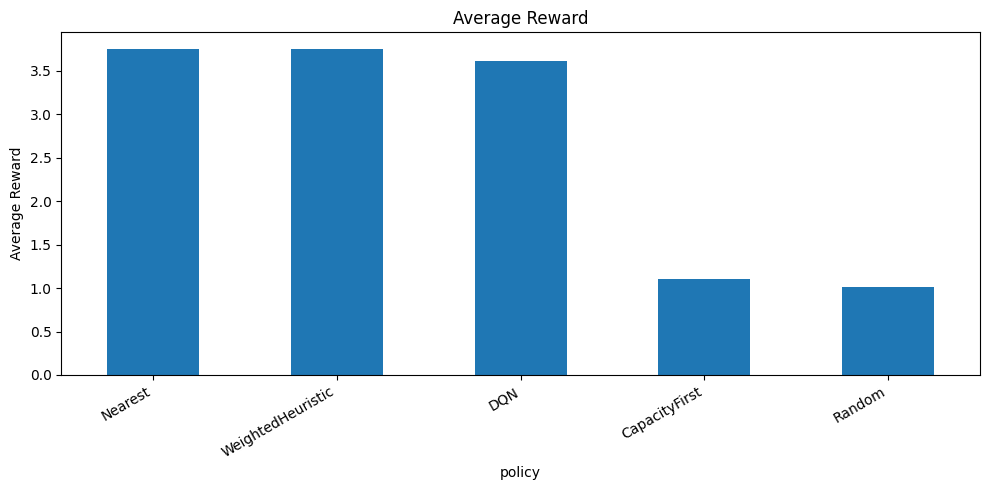

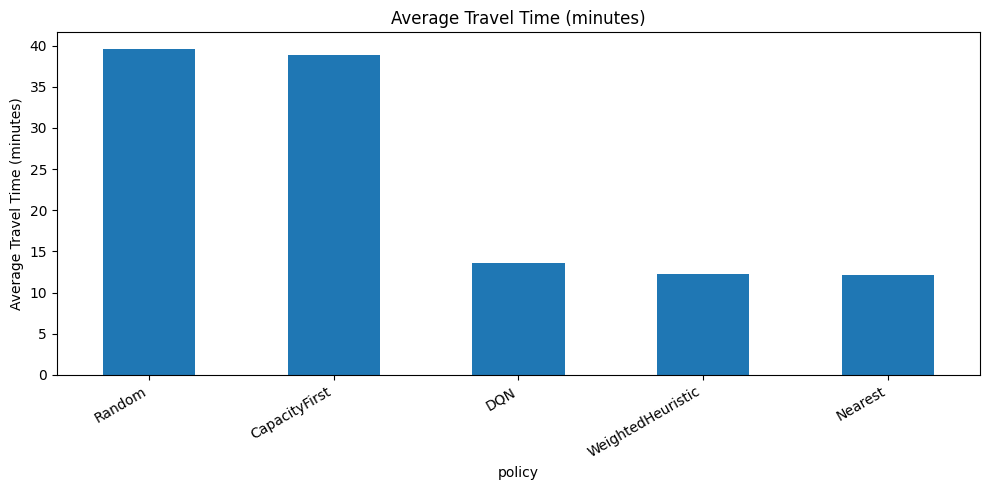

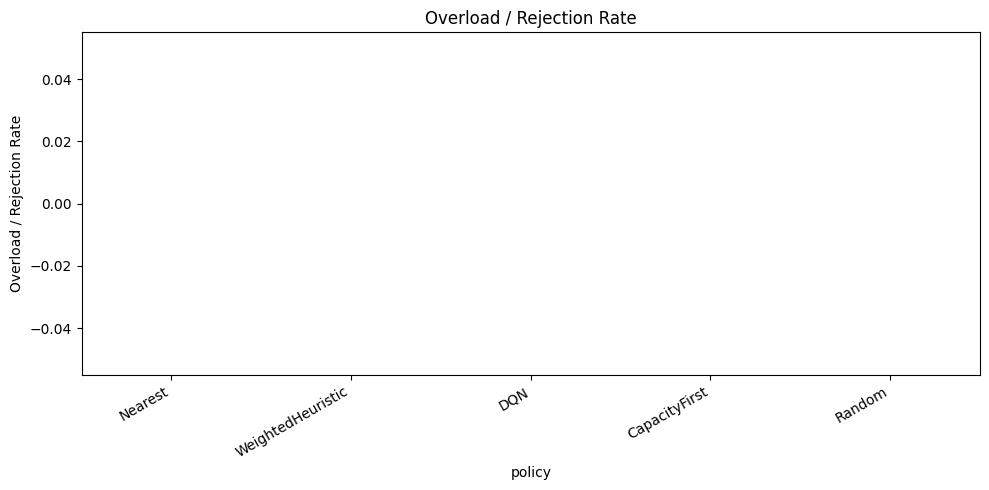

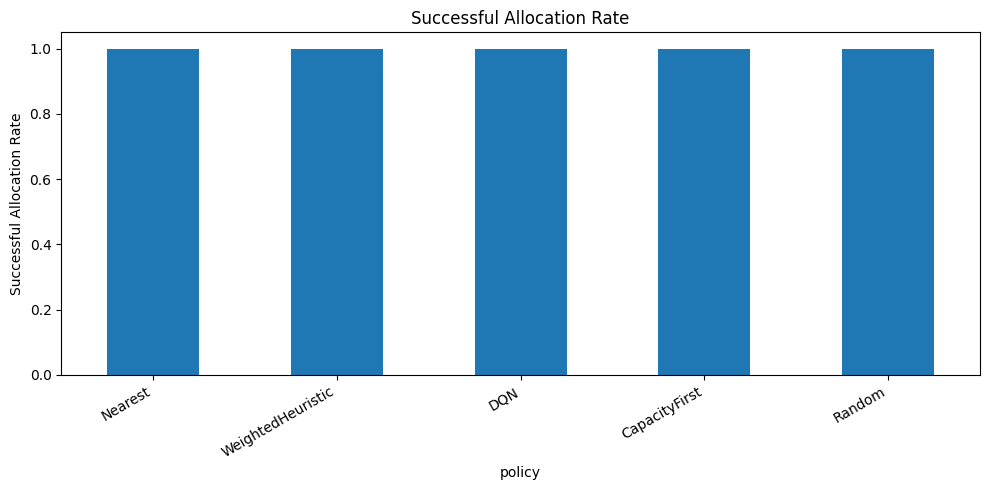

In [25]:
# ============================================================
# CELL 25 — POLICY COMPARISON PLOTS
# ============================================================
for col, title in [
    ("mean_reward", "Average Reward"),
    ("mean_travel_min", "Average Travel Time (minutes)"),
    ("overload_rate", "Overload / Rejection Rate"),
    ("success_rate", "Successful Allocation Rate")
]:
    plt.figure(figsize=(10, 5))
    summary_normal[col].sort_values(ascending=False).plot(kind="bar")
    plt.title(title)
    plt.ylabel(title)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(CACHE_DIR / f"policy_comparison_{col}.png", dpi=300)
    plt.show()

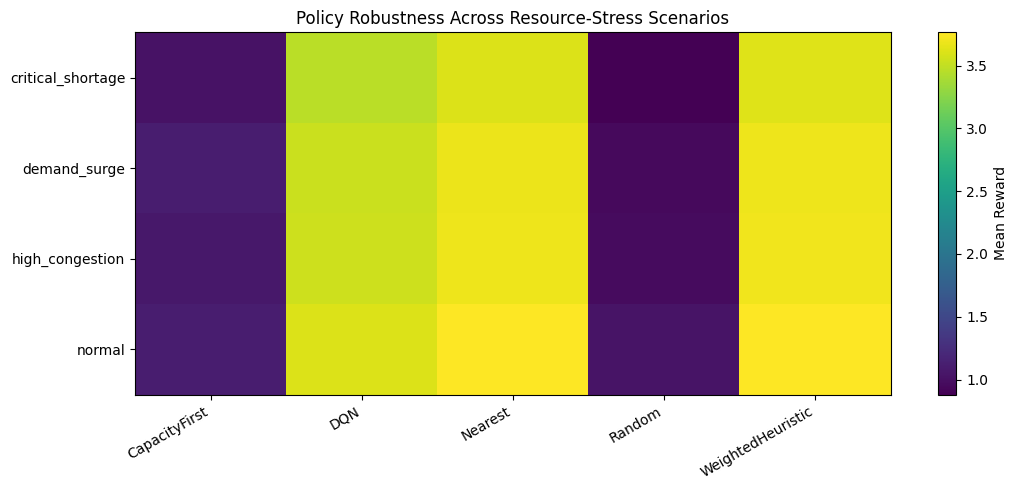

policy,CapacityFirst,DQN,Nearest,Random,WeightedHeuristic
stress,,,,,
critical_shortage,1.027,3.467,3.617,0.882,3.623
demand_surge,1.118,3.536,3.685,0.952,3.694
high_congestion,1.068,3.548,3.696,0.963,3.700
normal,1.112,3.616,3.764,1.030,3.762


In [26]:
# ============================================================
# CELL 26 — STRESS-TEST HEATMAP
# ============================================================
pivot = stress_summary.pivot(
    index="stress",
    columns="policy",
    values="reward"
)

plt.figure(figsize=(11, 5))
plt.imshow(pivot.values, aspect="auto")
plt.xticks(
    range(len(pivot.columns)),
    pivot.columns,
    rotation=30,
    ha="right"
)
plt.yticks(range(len(pivot.index)), pivot.index)
plt.colorbar(label="Mean Reward")
plt.title("Policy Robustness Across Resource-Stress Scenarios")
plt.tight_layout()
plt.savefig(CACHE_DIR / "stress_test_heatmap.png", dpi=300)
plt.show()

display(pivot.round(3))

In [27]:
# ============================================================
# CELL 27 — FIND AN INTERESTING DQN DECISION
# ============================================================
env = EmergencyAllocationEnv(
    test_events,
    stress="high_congestion",
    seed=SEED,
    episode_len=50
)

obs, _ = env.reset(seed=SEED)
example = None

for _ in range(100):
    row = env._event()
    distances = distance_matrix[int(row["zone_idx"])]

    dqn_action, _ = model.predict(obs, deterministic=True)
    dqn_action = int(dqn_action)

    nearest_action = choose_nearest(
        env.occupancy,
        distances,
        np.random.default_rng(SEED)
    )

    if dqn_action != nearest_action:
        example = {
            "row": row.copy(),
            "dqn_action": dqn_action,
            "nearest_action": nearest_action,
            "distances": distances.copy(),
            "occupancy": env.occupancy.copy()
        }
        break

    obs, _, terminated, truncated, _ = env.step(dqn_action)

    if terminated or truncated:
        obs, _ = env.reset(seed=SEED)

if example:
    r = example["row"]
    da = example["dqn_action"]
    na = example["nearest_action"]

    print("Incident:", r["incident_id"])
    print("ZIP spatial proxy:", r["zipcode"])
    print("Severity bin:", r["severity_bin"])
    print("DQN hospital:", hospitals.iloc[da]["facility_name"])
    print("Nearest hospital:", hospitals.iloc[na]["facility_name"])
    print("DQN distance (km):", round(example["distances"][da] / 1000, 2))
    print("Nearest distance (km):", round(example["distances"][na] / 1000, 2))
    print(
        "DQN utilization:",
        round(example["occupancy"][da] / hospital_capacity[da], 3)
    )
    print(
        "Nearest utilization:",
        round(example["occupancy"][na] / hospital_capacity[na], 3)
    )
else:
    print("No differing decision found in the search window.")

Incident: 82981438
ZIP spatial proxy: 11106
Severity bin: 2
DQN hospital: Melrose Houses Child Health Clinic
Nearest hospital: La Clinica Del Barrio
DQN distance (km): 9.01
Nearest distance (km): 5.4
DQN utilization: 0.005
Nearest utilization: 0.002


In [28]:
# ============================================================
# CELL 28 — OPTIONAL INTERACTIVE MAP
# ============================================================
try:
    import folium

    fmap = folium.Map(
        location=[
            hospitals["latitude"].mean(),
            hospitals["longitude"].mean()
        ],
        zoom_start=10,
        tiles="CartoDB positron"
    )

    for _, h in hospitals.iterrows():
        folium.Marker(
            [h["latitude"], h["longitude"]],
            popup=(
                f"{h['facility_name']} | "
                f"capacity={h['capacity']} | "
                f"source={h['capacity_source']}"
            )
        ).add_to(fmap)

    for _, r in test_events.sample(
        min(200, len(test_events)),
        random_state=SEED
    ).iterrows():
        folium.CircleMarker(
            [r["latitude"], r["longitude"]],
            radius=2,
            tooltip=(
                f"EMS ZIP {r['zipcode']} | "
                f"severity {r['severity_bin']}"
            )
        ).add_to(fmap)

    fmap.save(CACHE_DIR / "nyc_emergency_map.html")
    display(fmap)

except Exception as e:
    print("Folium map unavailable:", e)

In [29]:
# ============================================================
# CELL 29 — EXPORT RESULTS
# ============================================================
summary_normal.to_csv(
    CACHE_DIR / "normal_policy_results.csv"
)
stress_summary.to_csv(
    CACHE_DIR / "stress_policy_results.csv",
    index=False
)
multi_seed_summary.to_csv(
    CACHE_DIR / "multi_seed_results.csv"
)
critical_summary.to_csv(
    CACHE_DIR / "critical_case_results.csv"
)
fairness_summary.to_csv(
    CACHE_DIR / "fairness_results.csv",
    index=False
)

print("Result files saved in:", CACHE_DIR)

Result files saved in: results


# 5. How to report the project

### Strong research question

> **Can deep reinforcement learning dynamically allocate EMS demand to geographically distributed hospitals more effectively than distance-only and capacity-based heuristics under changing hospital resource constraints?**

### Recommended paper structure

1. Introduction
2. Related Work
3. Dataset and Problem Formulation
4. Privacy-Aware Spatial Preprocessing
5. Road-Network Routing
6. Dynamic Resource Allocation MDP
7. DQN Methodology
8. Baseline Policies
9. Experimental Design
10. Results
11. Critical-Case and Stress-Test Analysis
12. Limitations
13. Conclusion

### Important limitation language

The model is a **decision-support simulation**, not a clinical deployment system. Exact EMS incident coordinates are unavailable in the public dataset, so ZIP centroids are used. Live hospital occupancy is also unavailable in the selected public sources, so occupancy and service duration are simulated. Do not describe the system as using real-time bed occupancy.

### Base paper

**C. Hua and T. Zaman, “Optimal Dispatch in Emergency Service System via Reinforcement Learning,” arXiv:2010.07513 (2020).**

This is the closest conceptual reference because it formulates emergency dispatch as an MDP and develops temporal-difference learning for the dispatch problem. citeturn0academia24

### Additional reference

**M. Allen, K. Pearn and T. Monks, “Developing an OpenAI Gym-compatible framework and simulation environment for testing Deep Reinforcement Learning agents solving the Ambulance Location Problem,” arXiv:2101.04434 (2021).** citeturn0academia26

### Healthcare resource-allocation reference

**Y. Li et al., “Deep Reinforcement Learning for Efficient and Fair Allocation of Health Care Resources,” arXiv:2309.08560 (2023).** citeturn0academia25

# Final checklist before using the results in a paper/resume

- Run the notebook from a fresh Colab runtime.
- Confirm that EMS records are real and downloaded from NYC Open Data.
- Record the exact EMS date range and record count.
- Record the number of hospitals and their capacity-source breakdown.
- Save the exact DQN hyperparameters.
- Run all five evaluation seeds.
- Copy actual generated values into the paper; never invent results.
- Include at least one case where DQN chooses a farther but less-loaded hospital.
- Clearly state the ZIP-centroid limitation.
- Clearly state that occupancy/service duration is simulated.
- Do not claim clinical or real-time deployment.